In [1]:
# Test get_country_fields
from pathlib import Path
import sys
print(sys.executable)

# Identify project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Add project root to Python's module search path
sys.path.insert(0, str(PROJECT_ROOT))
from src.utils import get_country_fields

france_path = get_country_fields("FR", "France", "data")
kenya_path = get_country_fields("KE", "Kenya", "data")

/Users/robmoore/geoanalytics/geog313-assignments/assignment-7/.pixi/envs/default/bin/python
File already exists: data/FR_France.parquet. Skipping download.
File already exists: data/KE_Kenya.parquet. Skipping download.


In [2]:
# test load_fields
from src.utils import load_fields
# test load fields
france = load_fields(france_path)
kenya = load_fields(kenya_path)

print(type(france))
print(france.npartitions)
print(france.crs)
print(france.head())

<class 'dask_geopandas.expr.GeoDataFrame'>
81
OGC:CRS84
   metrics:area  metrics:perimeter      id    determination:datetime  \
0   4113.355957         353.254486  279745 2024-01-01 00:00:00+00:00   
1  30344.457031        1413.280151  279804 2024-01-01 00:00:00+00:00   
2  53741.164062        1279.683472  279803 2025-01-01 00:00:00+00:00   
3    567.141357         102.505760  279746 2024-01-01 00:00:00+00:00   
4   1843.065308         213.442795  279749 2024-01-01 00:00:00+00:00   

  determination:method                                           geometry  \
0         auto-imagery  POLYGON ((-1.22082 44.82727, -1.22082 44.82718...   
1         auto-imagery  POLYGON ((-1.13998 44.84659, -1.13998 44.8465,...   
2         auto-imagery  POLYGON ((-1.13962 44.84668, -1.13962 44.84659...   
3         auto-imagery  POLYGON ((-1.21373 44.84937, -1.21373 44.84928...   
4         auto-imagery  POLYGON ((-1.2087 44.85404, -1.2087 44.85395, ...   

                                                

In [3]:
# test verify_area
from src.utils import verify_area

#inspect a small sample of France
sample = france.head(10)

# check its original CRS
print(sample.crs)

# estimate a suitable UTM projection
target_crs = sample.estimate_utm_crs()

# reproject the sample
projected = sample.to_crs(target_crs)

# calculate area in square meters
calculated_area = projected.geometry.area

# compare against the original area values
print(sample["metrics:area"])
print(calculated_area)

# finally, test your utility function
comparison = verify_area(france, n=10)
print(comparison)


OGC:CRS84
0     4113.355957
1    30344.457031
2    53741.164062
3      567.141357
4     1843.065308
5      496.194550
6      425.312500
7      496.205170
8     4962.011719
9      141.770065
Name: metrics:area, dtype: float32
0     4112.066706
1    30336.302261
2    53726.745349
3      566.965609
4     1842.499112
5      496.042403
6      425.180836
7      496.052412
8     4960.479811
9      141.726132
dtype: float64
   computed_area  metrics:area
0    4112.066706   4113.355957
1   30336.302261  30344.457031
2   53726.745349  53741.164062
3     566.965609    567.141357
4    1842.499112   1843.065308
5     496.042403    496.194550
6     425.180836    425.312500
7     496.052412    496.205170
8    4960.479811   4962.011719
9     141.726132    141.770065


In [4]:
from src.utils import field_area_distribution
france_areas = field_area_distribution(france)
print(type(france_areas))
print(france_areas.head())

<class 'dask.dataframe.dask_expr._collection.Series'>
0     4113.355957
1    30344.457031
2    53741.164062
3      567.141357
4     1843.065308
Name: metrics:area, dtype: float32


In [5]:
# Load France and Kenya for a single chosen year, and report the number of fields in each.

france_path = get_country_fields("FR", "France", "data")
kenya_path = get_country_fields("KE", "Kenya", "data")

# load laxy dask gdf
france = load_fields(france_path)
kenya = load_fields(kenya_path)

# filter to 2024
france24 = france[france["determination:datetime"].dt.year == 2024]
kenya24 = kenya[kenya["determination:datetime"].dt.year == 2024]

france_shape = france24.shape[0].compute()
kenya_shape = kenya24.shape[0].compute()

print("France:", france_shape)
print("Kenya:", kenya_shape)

    

File already exists: data/FR_France.parquet. Skipping download.
File already exists: data/KE_Kenya.parquet. Skipping download.
France: 2644254
Kenya: 12964056


In [6]:
# take small sample of france 2024 and check crs
sample = france24.head()
print(sample.crs)

# calculate area without reprojecting
area_degrees = sample.geometry.area
print(area_degrees)

OGC:CRS84
0    4.680394e-07
1    3.453808e-06
3    6.455715e-08
4    2.098107e-07
5    5.648751e-08
dtype: float64


/var/folders/j1/0_sk538d7d98b54ykvvght1h0000gn/T/ipykernel_8718/329978490.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area_degrees = sample.geometry.area


In [7]:
# Estimate appropriate UTM CRS
target_crs = sample.estimate_utm_crs()

# reproject
projected = sample.to_crs(target_crs)

# calc area
area_meters = projected.geometry.area

print(area_meters)

0     4112.066706
1    30336.302261
3      566.965609
4     1842.499112
5      496.042403
dtype: float64


In [8]:
import pandas as pd
# comparison between UTM and 4326
comparison = pd.DataFrame({
    "area_degrees": area_degrees,
    "area_meters": area_meters,
    "provided_area": sample["metrics:area"]})
print(comparison)

   area_degrees   area_meters  provided_area
0  4.680394e-07   4112.066706    4113.355957
1  3.453808e-06  30336.302261   30344.457031
3  6.455715e-08    566.965609     567.141357
4  2.098107e-07   1842.499112    1843.065308
5  5.648751e-08    496.042403     496.194550


In [9]:
comparison["percent_diff"] = (
    (comparison["area_meters"] - comparison["provided_area"])
    / comparison["provided_area"]) * 100
print(comparison)

   area_degrees   area_meters  provided_area  percent_diff
0  4.680394e-07   4112.066706    4113.355957     -0.031343
1  3.453808e-06  30336.302261   30344.457031     -0.026874
3  6.455715e-08    566.965609     567.141357     -0.030988
4  2.098107e-07   1842.499112    1843.065308     -0.030720
5  5.648751e-08    496.042403     496.194550     -0.030663


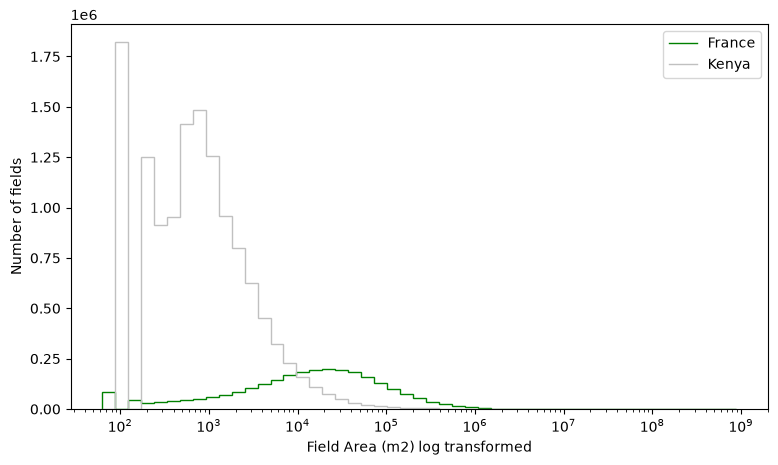

In [14]:
# plot the field distributions
france_areas = field_area_distribution(france24)
kenya_areas = field_area_distribution(kenya24)

# plot a histogram
import numpy as np
import matplotlib.pyplot as plt
import dask
import dask.array as da

fr_min, fr_max, ke_min, ke_max = dask.compute(
    france_areas.min(),
    france_areas.max(),
    kenya_areas.min(),
    kenya_areas.max()
)

min_area = min(fr_min, ke_min)
max_area = max(fr_max, ke_max)

bins = np.logspace(
    np.log10(min_area),
    np.log10(max_area),
    50
)

fr_counts, _ = da.histogram(
    france_areas.to_dask_array(lengths=True),
    bins=bins
)

ke_counts, _ = da.histogram(
    kenya_areas.to_dask_array(lengths=True),
    bins=bins
)

 # compute histogram counts
fr_counts, ke_counts = dask.compute(fr_counts, ke_counts)

# plot both distributions
fig, ax = plt.subplots(figsize=(9, 5))

ax.stairs(fr_counts, bins, label="France", color="green")
ax.stairs(ke_counts, bins, label="Kenya", color="silver")

# plot france and kenya distributions of field area
ax.set_xscale("log")
ax.set_xlabel("Field Area (m2) log transformed")
ax.set_ylabel("Number of fields")
ax.legend()
plt.show()

## France and Kenya comparison

The comparison below uses the same prediction year (2024) for both countries. Field-level confidence is a model certainty signal; it is not itself a measure of agricultural productivity or field quality. The field-size contrast is interpreted separately from the confidence contrast so that landscape structure is not confused with model certainty.

File already exists: data/FR_France.parquet. Skipping download.
File already exists: data/KE_Kenya.parquet. Skipping download.
Confidence statistics (2024):
                         France         Kenya
count              2.547945e+06  1.204572e+07
mean               8.904338e+01  7.348314e+01
std                1.215010e+01  1.673727e+01
min                1.194138e+01  5.786579e+00
25%                8.961832e+01  7.395086e+01
50%                9.442811e+01  8.125027e+01
75%                9.923092e+01  9.088290e+01
max                1.000000e+02  1.000000e+02
fraction_above_50  9.704613e-01  8.876119e-01


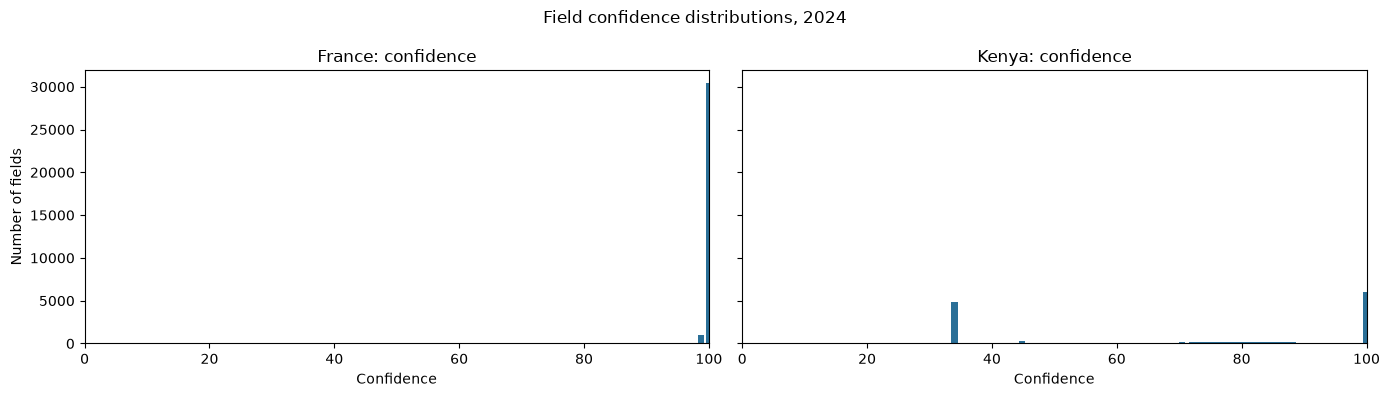

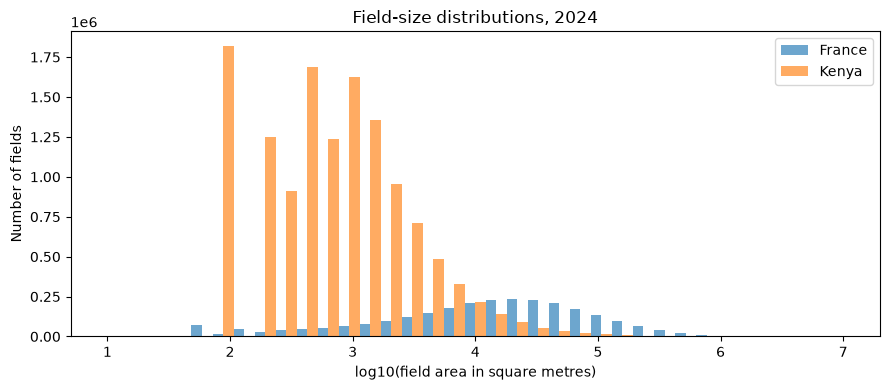

Field-size statistics (square metres, 2024):
             France         Kenya
count  2.644254e+06  1.296406e+07
mean   5.299563e+04  5.761604e+03
std    1.765860e+05  7.991523e+05
min    6.293808e+01  9.896158e+01
25%    7.635669e+03  3.973193e+02
50%    2.597142e+04  9.932515e+02
75%    1.788727e+05  8.740914e+03
max    6.995438e+07  8.892188e+08


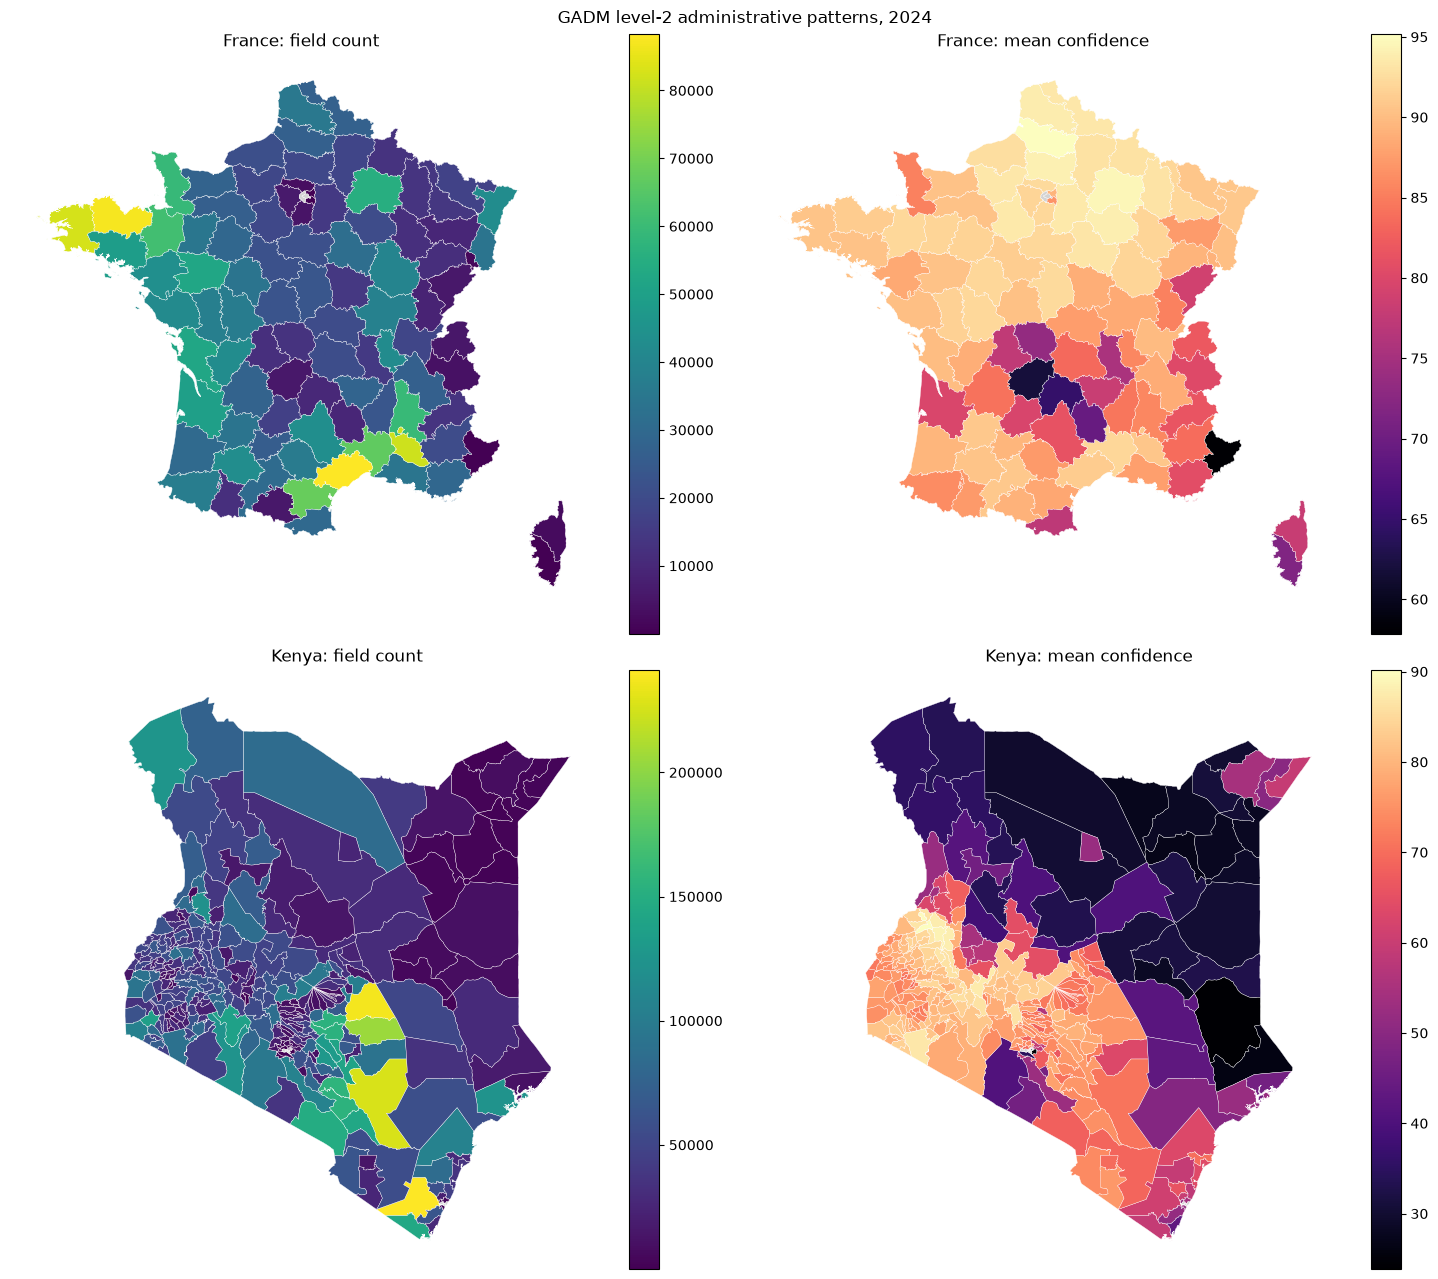

In [1]:
import dask
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from src.utils import (
    admin_stats,
    confidence_summary,
    field_area_distribution,
    get_country_fields,
    join_to_admin,
    load_fields,
)

# Keep both countries on the same prediction year and load fields lazily.
france_path = get_country_fields("FR", "France", "data")
kenya_path = get_country_fields("KE", "Kenya", "data")
france = load_fields(france_path)
kenya = load_fields(kenya_path)
france24 = france[france["determination:datetime"].dt.year == 2024]
kenya24 = kenya[kenya["determination:datetime"].dt.year == 2024]

# These are small aggregate results; the field tables remain Dask-backed.
france_conf = confidence_summary(france24, threshold=50)
kenya_conf = confidence_summary(kenya24, threshold=50)
confidence_stats = pd.DataFrame(
    {
        "France": france_conf["summary"],
        "Kenya": kenya_conf["summary"],
    }
)
confidence_stats.loc["fraction_above_50"] = [
    france_conf["fraction_above_threshold"],
    kenya_conf["fraction_above_threshold"],
]
print("Confidence statistics (2024):")
print(confidence_stats)

# Plot confidence distributions from the compact value-count results.
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for axis, label, result in zip(
    axes, ["France", "Kenya"], [france_conf, kenya_conf]
):
    distribution = result["distribution"]
    axis.bar(distribution.index, distribution.values, width=1.0, color="#2a6f97")
    axis.set_title(f"{label}: confidence")
    axis.set_xlabel("Confidence")
    axis.set_xlim(0, 100)
axes[0].set_ylabel("Number of fields")
fig.suptitle("Field confidence distributions, 2024")
fig.tight_layout()
plt.show()

# Build field-size histograms by aggregating one histogram per Dask partition.
def log_area_histogram(areas, bins):
    values = areas[(areas > 0) & areas.notna()]
    return np.histogram(np.log10(values), bins=bins)[0]

france_areas = field_area_distribution(france24)
kenya_areas = field_area_distribution(kenya24)
area_quantiles = pd.concat(
    [
        france_areas.quantile([0.01, 0.99]).compute(),
        kenya_areas.quantile([0.01, 0.99]).compute(),
    ]
)
area_bins = np.linspace(
    np.floor(np.log10(area_quantiles.min())),
    np.ceil(np.log10(area_quantiles.max())),
    36,
)
def partition_histogram(area_series):
    delayed_histograms = [
        dask.delayed(log_area_histogram)(partition, bins=area_bins)
        for partition in area_series.to_delayed()
    ]
    return np.sum(dask.compute(*delayed_histograms), axis=0)

france_area_hist = partition_histogram(france_areas)
kenya_area_hist = partition_histogram(kenya_areas)
area_centres = (area_bins[:-1] + area_bins[1:]) / 2
width = area_bins[1] - area_bins[0]
fig, axis = plt.subplots(figsize=(9, 4))
axis.bar(area_centres - width / 4, france_area_hist, width / 2, alpha=0.65, label="France")
axis.bar(area_centres + width / 4, kenya_area_hist, width / 2, alpha=0.65, label="Kenya")
axis.set_xlabel("log10(field area in square metres)")
axis.set_ylabel("Number of fields")
axis.set_title("Field-size distributions, 2024")
axis.legend()
plt.tight_layout()
plt.show()

area_stats = pd.DataFrame(
    {
        "France": france_areas.describe().compute(),
        "Kenya": kenya_areas.describe().compute(),
    }
)
print("Field-size statistics (square metres, 2024):")
print(area_stats)

# GADM level-2 boundaries are read as GeoDataFrames and kept in EPSG:4326.
france_admin = gpd.read_file(
    "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_FRA_2.json"
).to_crs("EPSG:4326")
kenya_admin = gpd.read_file(
    "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_KEN_2.json"
).to_crs("EPSG:4326")

france_joined = join_to_admin(france24, france_admin)
kenya_joined = join_to_admin(kenya24, kenya_admin)
france_admin_stats = admin_stats(france_joined).compute().reset_index()
kenya_admin_stats = admin_stats(kenya_joined).compute().reset_index()
france_map = france_admin.merge(france_admin_stats, on="GID_2", how="left")
kenya_map = kenya_admin.merge(kenya_admin_stats, on="GID_2", how="left")

fig, axes = plt.subplots(2, 2, figsize=(15, 13))
map_specs = [
    (france_map, "field_count", "France: field count", axes[0, 0]),
    (france_map, "mean_confidence", "France: mean confidence", axes[0, 1]),
    (kenya_map, "field_count", "Kenya: field count", axes[1, 0]),
    (kenya_map, "mean_confidence", "Kenya: mean confidence", axes[1, 1]),
]
for admin_map, column, title, axis in map_specs:
    admin_map.plot(
        ax=axis,
        column=column,
        cmap="viridis" if column == "field_count" else "magma",
        legend=True,
        missing_kwds={"color": "lightgrey", "label": "No assigned fields"},
        edgecolor="white",
        linewidth=0.25,
    )
    axis.set_title(title)
    axis.set_axis_off()
fig.suptitle("GADM level-2 administrative patterns, 2024")
fig.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Export compact tables for reuse without rerunning the country-level analysis.
confidence_stats.to_csv(results_dir / "confidence_statistics_2024.csv")
area_stats.to_csv(results_dir / "field_size_statistics_2024.csv")
france_admin_stats.to_csv(results_dir / "france_admin_statistics_2024.csv", index=False)
kenya_admin_stats.to_csv(results_dir / "kenya_admin_statistics_2024.csv", index=False)

# Export the confidence distribution figure.
confidence_figure, confidence_axes = plt.subplots(
    1, 2, figsize=(14, 4), sharey=True
)
for axis, label, result in zip(
    confidence_axes, ["France", "Kenya"], [france_conf, kenya_conf]
):
    distribution = result["distribution"]
    axis.bar(distribution.index, distribution.values, width=1.0, color="#2a6f97")
    axis.set_title(f"{label}: confidence")
    axis.set_xlabel("Confidence")
    axis.set_xlim(0, 100)
confidence_axes[0].set_ylabel("Number of fields")
confidence_figure.suptitle("Field confidence distributions, 2024")
confidence_figure.tight_layout()
confidence_figure.savefig(
    results_dir / "confidence_distributions_2024.png", dpi=200, bbox_inches="tight"
)
plt.show()

# Export the field-size distribution figure.
area_figure, area_axis = plt.subplots(figsize=(9, 4))
area_axis.bar(
    area_centres - width / 4,
    france_area_hist,
    width / 2,
    alpha=0.65,
    label="France",
)
area_axis.bar(
    area_centres + width / 4,
    kenya_area_hist,
    width / 2,
    alpha=0.65,
    label="Kenya",
)
area_axis.set_xlabel("log10(field area in square metres)")
area_axis.set_ylabel("Number of fields")
area_axis.set_title("Field-size distributions, 2024")
area_axis.legend()
area_figure.tight_layout()
area_figure.savefig(
    results_dir / "field_size_distributions_2024.png", dpi=200, bbox_inches="tight"
)
plt.show()

# Export each requested choropleth as a standalone map.
for admin_map, country in [(france_map, "france"), (kenya_map, "kenya")]:
    for column, label in [
        ("field_count", "field_count"),
        ("mean_confidence", "mean_confidence"),
    ]:
        map_figure, map_axis = plt.subplots(figsize=(8, 8))
        admin_map.plot(
            ax=map_axis,
            column=column,
            cmap="viridis" if column == "field_count" else "magma",
            legend=True,
            missing_kwds={
                "color": "lightgrey",
                "label": "No assigned fields",
            },
            edgecolor="white",
            linewidth=0.25,
        )
        map_axis.set_title(f"{country.title()}: {label.replace('_', ' ')}, 2024")
        map_axis.set_axis_off()
        map_figure.tight_layout()
        map_figure.savefig(
            results_dir / f"{country}_{label}_2024.png",
            dpi=200,
            bbox_inches="tight",
        )
        plt.show()

print(f"Exported analysis tables and figures to {results_dir.resolve()}")

### Interpretation

France has a larger and more concentrated field-size distribution, consistent with more mechanized, consolidated agriculture, while Kenya has many smaller fields, consistent with predominantly smallholder production; the field-count maps show where those patterns are concentrated within each country. Differences in mean confidence and in the confidence distributions describe model certainty, not a second measure of the landscape: a lower Kenyan confidence pattern may reflect the model's stated caveat that smallholder systems are harder to represent, in addition to genuine boundary complexity and heterogeneity. France's higher confidence, where observed, therefore should not be read as proof that its agriculture is intrinsically more productive, and Kenya's lower confidence should not be read as proof that its fields are less real. Taken together, the field-size maps describe landscape and farming-system structure, while the confidence maps describe how certain the model is about the mapped structure.

### Analytical correction

An early analysis mistake was to inspect `geometry.area` while the fields were still in `EPSG:4326`; those values are in square degrees and cannot be compared across countries or to `metrics:area`. The error was caught by comparing the result with `verify_area`, which reprojects a sample to a metric CRS and agrees with the supplied square-metre areas. The final analysis keeps field operations lazy, filters both countries to 2024 before comparison, uses the `within` spatial-join predicate, and calculates administrative area in projected `EPSG:6933` before computing coverage.